# 01 · The Bayes filter, and a grid that implements it exactly

Every filter in this series is an approximation of one recursion, the **Bayes filter**. This
notebook derives it, then implements it with no approximation other than discretisation, on a
grid. The grid filter will show what the "true" belief looks like (sometimes it has two
bumps), and why we cannot use a grid in general.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path().resolve().parent))

import time
import numpy as np
import matplotlib.pyplot as plt
from bayesian_filters import World, simulate, GridFilter, run_filter, position_error, motion_model
from bayesian_filters import viz
viz.style()

## 1. The recursion

Write $z_{1:t} = (z_1,\dots,z_t)$ and $u_{1:t}$ likewise. The **belief** is the posterior
$$\operatorname{bel}(x_t) = p(x_t \mid z_{1:t}, u_{1:t}).$$
We want $\operatorname{bel}(x_{t+1})$ from $\operatorname{bel}(x_t)$, the new control $u_{t+1}$ and the new
measurement $z_{t+1}$, without going back through the whole history. Two modelling
assumptions make this possible (notebook 00):

* **Markov motion**: $p(x_{t+1} \mid x_{0:t}, z_{1:t}, u_{1:t+1}) = p(x_{t+1} \mid x_t, u_{t+1})$;
* **conditionally independent measurements**: $p(z_{t+1} \mid x_{0:t+1}, z_{1:t}, u_{1:t+1}) = p(z_{t+1} \mid x_{t+1})$.

**Predict** (total probability, then the Markov assumption, then the fact that $u_{t+1}$
alone says nothing about $x_t$):
$$
\overline{\operatorname{bel}}(x_{t+1}) \;=\; p(x_{t+1}\mid z_{1:t},u_{1:t+1})
\;=\; \int p(x_{t+1}\mid x_t,u_{t+1})\,\operatorname{bel}(x_t)\,\mathrm d x_t .
$$
This is the Chapman–Kolmogorov equation: the belief is pushed through the motion model
and *spreads out*.

**Update** (Bayes' rule, then the measurement assumption):
$$
\operatorname{bel}(x_{t+1}) \;=\; \frac{p(z_{t+1}\mid x_{t+1})\;\overline{\operatorname{bel}}(x_{t+1})}{\int p(z_{t+1}\mid x')\,\overline{\operatorname{bel}}(x')\,\mathrm d x'} \;=\; \eta\, p(z_{t+1}\mid x_{t+1})\,\overline{\operatorname{bel}}(x_{t+1}).
$$
The prediction is *re-weighted* by the likelihood of what was seen and renormalised; the
belief *sharpens*.

Neither integral has a closed form in general. The rest of the series is a catalogue of ways to
compute them:

| | belief | predict | update |
|---|---|---|---|
| grid (this notebook) | table of cell probabilities | shift + convolution | multiply + normalise |
| KF (02) | Gaussian | exact (linear model) | exact (linear model) |
| EKF (03) | Gaussian | linearise $f$ | linearise $h$ |
| UKF (04) | Gaussian | sigma points through $f$ | sigma points through $h$ |
| PF (05) | weighted samples | sample $p(x_{t+1}\mid x_t,u)$ | weight by $p(z\mid x)$, resample |

## 2. A grid filter for the mower's position

To keep the table two-dimensional we give the mower a **compass**, so the heading is (almost)
known and only the position $(p^x, p^y)$ is uncertain. The lawn is cut into $4\times 4$ cells
($80 \times 80 = 6400$ cells).

* **Predict.** With the heading known, the motion is a translation by
  $s\,(\cos\theta, \sin\theta)$ plus noise. The integral is a convolution: shift the table, then
  blur it with a Gaussian kernel whose width is the motion noise
  (`scipy.ndimage.shift` and `gaussian_filter`).
* **Update.** Multiply cell by cell by $p(z \mid \text{cell centre})$ and renormalise.

We make the problem hard on purpose: the mower only measures **ranges** (no bearings) to only
**two** landmarks. Two circles meet in two points, so the true posterior is **bimodal**.

In [2]:
world4 = World.default()
world = World(world4.landmarks[:2])  # only L0 and L1
run = simulate(world, n_steps=400, seed=1)

grid = GridFilter(world, cell=4.0, sensor="range")
snap_at = [0, 1, 4, 9, 40]
snaps, t0 = {}, time.perf_counter()
for t in range(run.n_steps):
    grid.predict_from_run(run, t)
    grid.update_from_run(run, t)
    if t in snap_at:
        snaps[t] = (grid.belief.copy(), grid.mean, grid.mode)
print(f"{run.n_steps} steps on {grid.belief.size} cells: {time.perf_counter() - t0:.2f} s")

400 steps on 6400 cells: 0.52 s


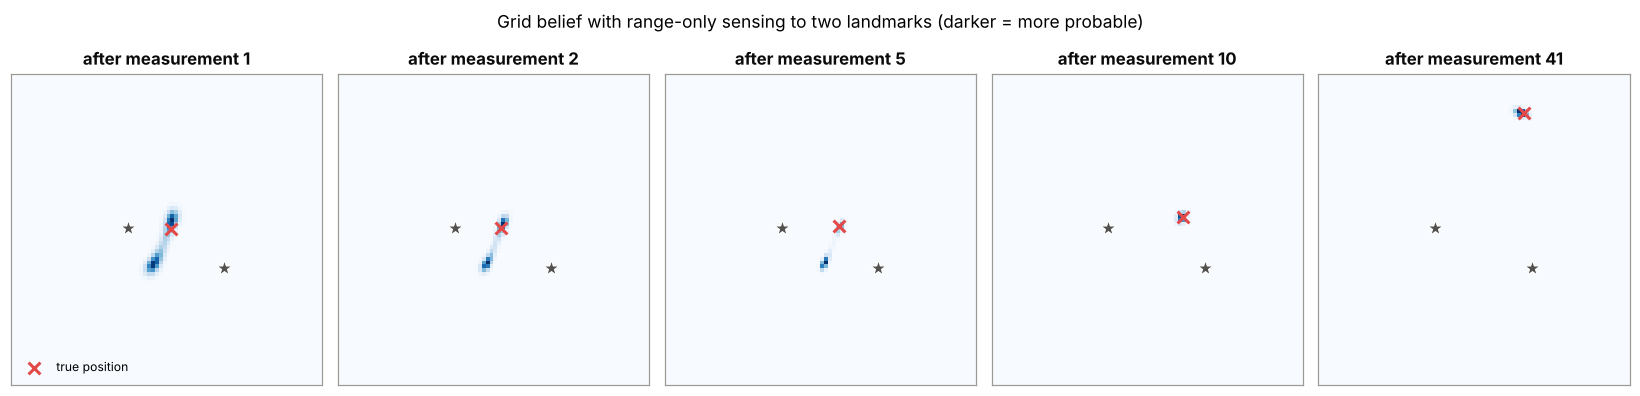

In [3]:
fig, axes = plt.subplots(1, len(snap_at), figsize=(15, 3.5))
ext = [-world.half_width, world.half_width, -world.half_height, world.half_height]
for ax, t in zip(axes, snap_at):
    b, m, mode = snaps[t]
    ax.imshow(b, origin="lower", extent=ext, cmap=viz.SEQ_CMAP, interpolation="nearest")
    ax.scatter(*world.landmarks.T, marker="*", s=120, c=viz.INK_2, ec="white", lw=0.8)
    ax.scatter(*run.truth[t + 1, :2], marker="x", s=60, c="#e34948", lw=2, label="true position")
    ax.set_title(f"after measurement {t + 1}")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Grid belief with range-only sensing to two landmarks (darker = more probable)", y=1.02)
plt.tight_layout(); plt.show()

* After the **first** measurement the belief is concentrated where two rings intersect: two
  symmetric bumps, mirror images across the line through the landmarks. The data cannot yet
  tell which side of that line the mower is on.
* As the mower moves, the prediction carries **both** hypotheses along. For a while the
  mirror track explains the ranges about as well as the true one. After 5 measurements the
  filter even puts almost all its mass on the **wrong** bump. The probability of the true
  bump is small, but it is not zero.
* Because that mass was kept, the mower's turn breaks the symmetry a few steps later, and by
  measurement 10 the belief is on the right bump and stays there.

A Gaussian belief cannot represent that phase: it would put its mean *between* the two
bumps, where the mower certainly is not. A filter that had committed to the most probable
bump at measurement 5 would never have come back.

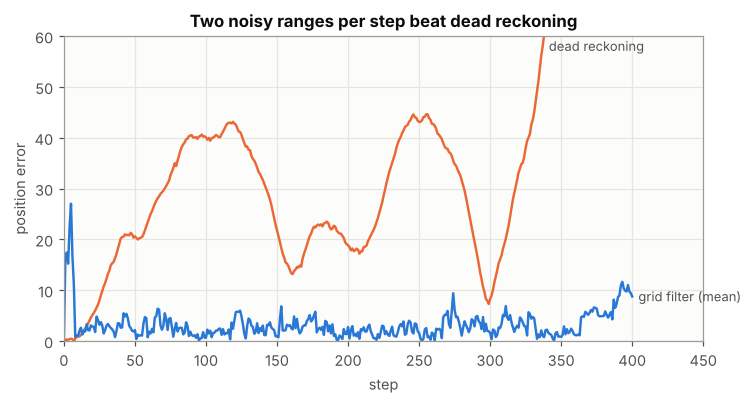

grid filter: median error 2.53 after step 20 (cell size 4.0, range noise sigma = 5.0)


In [4]:
res = run_filter(GridFilter(world, cell=4.0, sensor="range"), run)
err_mean = position_error(res.means, run.truth)

dr = [run.truth[0]]
for u in run.controls:
    dr.append(motion_model(dr[-1], u))
err_dr = position_error(np.array(dr), run.truth)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(err_dr, color=viz.COLORS["UKF"], lw=1.6)
ax.plot(err_mean, color=viz.COLORS["Grid"], lw=1.6)
ax.set_xlabel("step"); ax.set_ylabel("position error"); ax.set_ylim(0, 60); ax.set_xlim(0, 450)
viz.label_line_end(ax, err_dr, "dead reckoning")
viz.label_line_end(ax, err_mean, "grid filter (mean)")
ax.set_title("Two noisy ranges per step beat dead reckoning")
plt.show()
print(f"grid filter: median error {np.median(err_mean[20:]):.2f} after step 20 "
      f"(cell size {grid.cell}, range noise sigma = {world.sigma_range})")

The filter's error is a fraction of the range noise: it fuses all past ranges through the
motion model, so no single noisy range is trusted on its own. The remaining error is partly
the discretisation: cells are 4 units wide.

## 3. Why not always use a grid?

The grid is exact up to discretisation and represents *any* belief. Its cost is the number of
cells: $n^d$ for $n$ bins per dimension in $d$ dimensions. Here $d = 2$. Without the compass we
need the heading too:

In [5]:
for d, label in [(2, "position (this notebook)"), (3, "pose (x, y, theta)"), (6, "pose + velocities"), (9, "a small drone")]:
    print(f"d = {d}: {80**d:>22,d} cells   {label}")

d = 2:                  6,400 cells   position (this notebook)
d = 3:                512,000 cells   pose (x, y, theta)
d = 6:        262,144,000,000 cells   pose + velocities
d = 9: 134,217,728,000,000,000 cells   a small drone


Three dimensions is still feasible (the classic *Markov localisation* of the 1990s), but the
cost grows exponentially with $d$. Moreover, most cells are almost surely empty at any time.
There are two ways out:

1. **Assume a shape** for the belief, a Gaussian, so that it is described by a mean and a
   covariance ($d + d(d+1)/2$ numbers): the Kalman family, notebooks 02–04.
2. **Sample** the belief: put the computing effort only where the probability is, using
   particles. This is the particle filter, notebook 05.

### Things to try
* Use `sensor="range_bearing"`: the bimodality disappears, because a bearing tells the side.
* Use all four landmarks (`world4`): ambiguous configurations become rare.
* Make the cells larger (`cell=10`): faster, but the error floor rises.